# CORRECTED NOTEBOOK -- re-run with *Kernel > Restart & Run All*

Only these lines were changed (everything else is identical to the original):

- cell 29: GlcMethylKaempferol SMILES with defined beta-D-glucoside stereochemistry

All outputs were cleared because the scores of the corrected compounds change.

# Molecular docking -- Lamium_amplexicaule vs ACE (1O86)



In [1]:
from pymol import cmd
import py3Dmol

from vina import Vina

from openbabel import pybel

from rdkit import Chem
from rdkit.Chem import AllChem, Draw

from meeko import MoleculePreparation

import MDAnalysis as mda
from MDAnalysis.coordinates import PDB

import prolif as plf
from prolif.plotting.network import LigNetwork


import sys, os
sys.path.insert(1, "/home/ali/medical plants/docking/Jupyter_Dock-main/utilities/")
from utils import fix_protein, getbox, generate_ledock_file, pdbqt_to_sdf, dok_to_sdf


import warnings
warnings.filterwarnings("ignore")
%config Completer.use_jedi = False

/home/ali/Downloads/or/envs/jupdock_clean/lib/python3.10/site-packages/MDAnalysis/topology/tables.py:52: DeprecationWarning: Deprecated in version 2.8.0
MDAnalysis.topology.tables has been moved to MDAnalysis.guesser.tables. This import point will be removed in MDAnalysis version 3.0.0
  warnings.warn(wmsg, category=DeprecationWarning)


It's a good idea to run the test protocols before attempting custom projects. Later, the user can specify the location of his/her project and save all of the files separately.

In [2]:
os.chdir('/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/')


## 1. Feching system and cleanup

Implementing Pymol is a simple way to download PDB structures. The user can launch this or any other Jupyter Dock's protocol by providing his or her own files.

In [3]:
cmd.fetch(code='1O86', type='pdb1')

# Zinc RETAINED: matches the published protocol for this exact system
# (Nwokocha et al. 2025, IJMS 26:10228), which explicitly retains Zn2+ in
# the ACE receptor "to maintain physiological relevance" and reports a
# successful redocking (RMSD 1.201 Å) using standard AutoDock Vina --
# no AD4Zn/metal-aware scoring needed. Zinc is not scored directly by
# standard Vina, but its steric presence still shapes the pocket geometry
# used by the search.
cmd.select(name='Prot', selection='polymer.protein or (resn ZN and chain A)')
cmd.save(filename='1O86_clean.pdb', format='pdb', selection='Prot', state=1)

cmd.select(name='NativeLig', selection='resn LPR and chain A')
_natlig_model = cmd.get_model('NativeLig', state=1)
print("Native ligand (lisinopril) atom count:", len(_natlig_model.atom))
cmd.save(filename='1O86_native_lig.mol2', format='mol2', selection='NativeLig', state=1)
cmd.delete('all')


Native ligand (lisinopril) atom count: 29


## 2. Protein and ligand sanitization

### 2.1. Protein Sanitization

#### Method 1: LePro -- NOT used for this target

For every other target in this study, LePro is the preferred receptor-
preparation tool. For ACE (1O86) specifically, LePro is skipped: it has no
concept of metal coordination and cannot correctly assign the tautomeric
state of the two histidines that coordinate the catalytic zinc. Receptor
preparation for this target instead uses Meeko's `mk_prepare_receptor.py`
with an explicit tautomer assignment for those two residues (see the code
cell below, Section 2.1).


In [4]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" # Launch this cell to see parameters


************************************************************
*      LePro                                               *
*            Add hydrogen atoms to a protein &             *
*            write the input file for LeDock               *
*      Copyright (C) 2013-21 Hongtao Zhao, PhD             *
*      Email: htzhaovv@gmail.com                           *
************************************************************
----------Usage:                                                                       
          lepro [PDB file] [-rot || -metal || -p]                                        
          -rot  [[chain] resid] align principal axes of the binding site with Cartesian
          -metal keep ZN/MN/CA/MG                                                      
          -metal -p redistribute metal charge to protein                               



In [5]:
# Receptor preparation switched from LePro to Meeko's mk_prepare_receptor.py
# for this target specifically. Rationale: LePro adds hydrogens with no
# concept of metal coordination, so it cannot correctly choose which
# tautomeric nitrogen (ND1 vs NE2) carries the free proton on ACE's two
# zinc-coordinating histidines -- a wrong choice there corrupts the local
# electrostatics exactly where lisinopril's carboxylate needs to coordinate
# the zinc. This project's AD4Zn receptor-prep notebook already solved this
# for the same residues by explicit assignment, confirmed by a distance
# check (His383/NE2 and His387/NE2 both ~2.0 A from Zn -> the free/
# protonated nitrogen is ND1 -> HID tautomer). Applying that same, already-
# verified assignment here.
!mk_prepare_receptor.py -i 1O86_clean.pdb -o 1O86_clean_H -p -n "A:383=HID,A:387=HID" --delete_bad_res

assert os.path.exists('1O86_clean_H.pdbqt'), "Meeko receptor prep failed -- check output above"

# Verify both the zinc and the HID assignment actually made it into the
# prepared receptor before trusting any downstream docking result.
_receptor_text = open('1O86_clean_H.pdbqt').read()
print("ZN in 1O86_clean_H.pdbqt:", "ZN" in _receptor_text)

# 1O86_clean_H.pdb is not produced by Meeko (PDBQT-only output here); keep
# a copy under the old filename purely for the later py3Dmol visualisation
# cell, which just needs a viewable structure, not the exact docking input.
import shutil
shutil.copy('1O86_clean.pdb', '1O86_clean_H.pdb')


Template padding will be used.
 gasteiger charges will be read from template file 
 
@> 4661 atoms and 1 coordinate set(s) were parsed in 0.02s.
No template matched for residue_key='A:40'
tried 6 templates for residue_key='A:40'excess_H_ok=False
ASP        heavy_miss=3 heavy_excess=0 H_excess=[] bond_miss={4} bond_excess=set()
NASP       heavy_miss=3 heavy_excess=0 H_excess=[] bond_miss=set() bond_excess=set()
CASP       heavy_miss=4 heavy_excess=0 H_excess=[] bond_miss={5} bond_excess={1}
ASH        heavy_miss=3 heavy_excess=0 H_excess=[] bond_miss={4} bond_excess=set()
CASH       heavy_miss=4 heavy_excess=0 H_excess=[] bond_miss={5} bond_excess={1}
NASH       heavy_miss=3 heavy_excess=0 H_excess=[] bond_miss=set() bond_excess=set()

No template matched for residue_key='A:64'
tried 6 templates for residue_key='A:64'excess_H_ok=False
GLU        heavy_miss=4 heavy_excess=0 H_excess=[] bond_miss=set() bond_excess=set()
NGLU       heavy_miss=4 heavy_excess=0 H_excess=[] bond_miss=set() bo

'1O86_clean_H.pdb'

#### Method 2: fix_protein (PDBFixer)

For proteins with missing amino acids or residues, or to ensure a more thorough sanitization of protein Jupyter Dock includes the _fix_protein()_ function, which employs PDBFixer to correct a wide range of common errors in protein pdb files. Furthermore, PDBFixer enables the assignment of pH-dependent protonation states to proteins.


>**Warning 1:**  It is possible to encounter problems with protein fixing when using **_fix_protein()_** and AutoDock Tools' **_prepare_receptor_** or when running LeDock. To resolve the issue, it is best to set the parameter _-A hydrogens_ in _prepare receptor_.


>**Hint:** PDBFixer is a great solution for many systems because it can solve serious problems in PDB files. As a result, PDBFixer renumbers the residues beginning with 1 regardless of the numbering on the original PDB file. To address this issue, the **_fix_protein()_** function includes a protocol for atomically renumbering the residues in accordance with the original PDB file.


**_fix_protein ( params )_**

Params:
      
  - **filename**: _str or path-like_ ; input file containing protein struture to be modified, file extrension must be pdb

  - **addHs_pH**: _float_ ; Add hydrogens at user defined pH

  - **try_renumberResidues**: _bool_ ; By default PDBFixer renumarets residues starting in 1, this option tries to recover originar residues numbering
    
  - **output**: _str or path-like_ ; output filename, extension must be pdb

```
fix_protein(filename='1O86_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1O86_clean_H.pdb')
```

## 4. Docking with AutoDock Vina

AutoDock Vina (Vina) is one of the docking engines in the AutoDock Suite, together with AutoDock4 (AD4), AutoDockGPU, AutoDockFR, and AutoDock-CrankPep, and arguably among the most widely used and successful docking engines. The reasons for this success are mostly due to its ease of use and its speed (up to 100x faster than AD4), when compared to the other docking engines in the suite and elsewhere, as well as being open source.

### 4.1. Protein preparation

After sanitization, the protein docking preparation includes converting it to the PDBQT file format, which stores the atomic coordinates, partial charges, and AutoDock atom types for both the receptor and the ligand. 

>**Hint:** Despite the fact that the PDBQT format includes changes (Q) and atom types (T) for molecular docking. The charges are not required for Autodock Vina, which computes electrostatic interactions using its own force field. Although, when using AutoDock instead of AutoDock Vina, the Q term is required. More information can be found here:https://autodock-vina.readthedocs.io/en/latest/introduction.html

#### Method 1: AutoDock Tools prepare_receptor

The AutoDock Tools are the best way to prepare the receptor for AutoDock Vina. Nonetheless, AutoDock Tools is a comprehensive suite of programs and scripts that are difficult to manage. Jupyter Dock execute the **_prepare receptor_** and **_prepare_ligand_** functions on their own. As a result, obtaining proper PDBQT files for AutoDock Vina has never been easier.

>**Warning:** There is currently only one method for preparing a PDBQT file for a receptor. It is expected that new methods apart from AutoDock Tools executables will be included in the near future into Jupyter Dock.

In [6]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" #Lauch this cell to see parameters


prepare_receptor4: receptor filename must be specified.
Usage: prepare_receptor4.py -r filename

    Description of command...
         -r   receptor_filename 
        supported file types include pdb,mol2,pdbq,pdbqs,pdbqt, possibly pqr,cif
    Optional parameters:
        [-v]  verbose output (default is minimal output)
        [-o pdbqt_filename]  (default is 'molecule_name.pdbqt')
        [-A]  type(s) of repairs to make: 
             'bonds_hydrogens': build bonds and add hydrogens 
             'bonds': build a single bond from each atom with no bonds to its closest neighbor
             'hydrogens': add hydrogens
             'checkhydrogens': add hydrogens only if there are none already
             'None': do not make any repairs 
             (default is 'None')
        [-C]  preserve all input charges ie do not add new charges 
             (default is addition of gasteiger charges)
        [-p]  preserve input charges on specific atom types, eg -p Zn -p Fe
        [-U]  cle

In [7]:
# No longer needed: AutoDockTools' prepare_receptor is not used for this
# target. Meeko's mk_prepare_receptor.py (cell above, Section 2.1) already
# produced 1O86_clean_H.pdbqt directly, with the explicit HID tautomer
# assignment this target requires. This cell is left in place only so the
# notebook's cell numbering/flow matches the rest of this study's
# notebooks; it performs no action.
assert os.path.exists('1O86_clean_H.pdbqt'), "Run the Meeko receptor-prep cell in Section 2.1 first."
print("Receptor already prepared via Meeko (see Section 2.1). Skipping AutoDockTools prepare_receptor.")


Receptor already prepared via Meeko (see Section 2.1). Skipping AutoDockTools prepare_receptor.


In [8]:
fix_protein(filename='1O86_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1O86_clean_H_fix.pdb')

## 7. Screening PHYTO compounds (Lamium_amplexicaule) against ACE (1O86)

Reuses the receptor (`1O86_clean_H.pdb`/`.pdbqt`, zinc retained) and the
docking box (native ligand lisinopril/LPR, chain A, `state=1`) prepared
above. Each compound docked in its own cell with its own uniquely-named
variables, seed pinned at 42. Source: Laggoune et al. 2008.

**Flag for Stigmasterol**: track record across this project so far is
mixed -- failed against COX-2/5IKQ (fixed by redocking vs 3NTG) and
against 5-LOX/3O8Y with the default box (fixed by widening), but worked
fine on the first try against AChE and Aldose Reductase. Section 7.3
includes the same widened-box/higher-exhaustiveness fallback in case the
default result here looks weak or the poses collapse after 1-2.

In [9]:
import os
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolDescriptors
from openbabel import openbabel as ob
from vina import Vina
import pandas as pd
import matplotlib.pyplot as plt

DOCKING_DIR = "/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/"
FIGURES_DIR = os.path.join(DOCKING_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.chdir(DOCKING_DIR)

RECEPTOR_PDB   = os.path.join(DOCKING_DIR, "1O86_clean_H.pdb")
RECEPTOR_PDBQT = os.path.join(DOCKING_DIR, "1O86_clean_H.pdbqt")
NATIVE_LIG     = os.path.join(DOCKING_DIR, "1O86_native_lig.mol2")

assert os.path.exists(RECEPTOR_PDBQT), "Run the receptor prep cells above first."
assert os.path.exists(NATIVE_LIG), "Run the native ligand extraction cell above first."

VINA_SEED = 42  # pinned for reproducibility

def prepare_ligand_from_smiles(name, smiles, n_confs=20):
    """SMILES -> multiple 3D conformers (ETKDGv3) -> MMFF94 minimize each ->
    keep lowest-energy conformer -> PDB -> PDBQT (AutoDockTools prepare_ligand,
    with OpenBabel fallback)."""
    import subprocess
    m = Chem.MolFromSmiles(smiles)
    m = Chem.AddHs(m)

    params = AllChem.ETKDGv3()
    params.randomSeed = 42
    conf_ids = AllChem.EmbedMultipleConfs(m, numConfs=n_confs, params=params)

    energies = []
    for cid in conf_ids:
        ff = AllChem.MMFFGetMoleculeForceField(m, AllChem.MMFFGetMoleculeProperties(m), confId=cid)
        if ff is None:
            continue
        ff.Minimize(maxIts=2000)
        energies.append((ff.CalcEnergy(), cid))
    if not energies:
        for cid in conf_ids:
            ff = AllChem.UFFGetMoleculeForceField(m, confId=cid)
            ff.Minimize(maxIts=2000)
            energies.append((ff.CalcEnergy(), cid))

    best_energy, best_cid = min(energies, key=lambda x: x[0])
    print(f"  {name}: {len(conf_ids)} conformers generated, "
          f"lowest energy = {best_energy:.2f} kcal/mol (conf {best_cid})")

    pdb_path   = os.path.join(DOCKING_DIR, f'_lig_{name}.pdb')
    pdbqt_path = os.path.join(DOCKING_DIR, f'_lig_{name}.pdbqt')
    Chem.MolToPDBFile(m, pdb_path, confId=best_cid)

    PREP_LIG_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand"
    result = subprocess.run([PREP_LIG_BIN, "-v", "-l", pdb_path, "-o", pdbqt_path],
                             capture_output=True, text=True)
    if not os.path.exists(pdbqt_path) or os.path.getsize(pdbqt_path) == 0:
        obConv = ob.OBConversion()
        obConv.SetInAndOutFormats('pdb', 'pdbqt')
        obmol = ob.OBMol()
        obConv.ReadFile(obmol, pdb_path)
        obConv.WriteFile(obmol, pdbqt_path)

    return pdbqt_path


### 7.1. Recompute the docking box (native ligand lisinopril, `state=1`)

In [10]:
# Box hardcoded to match the published protocol exactly (Nwokocha et al.
# 2025, IJMS 26:10228), rather than recomputed via getbox(): a 20x20x20 A
# cube centered on lisinopril's crystallographic centroid, vs. this
# notebook's previous 15.6 x 20.0 x 21.9 A getbox()-derived box, which was
# notably tighter on one axis than the published, successfully-validated
# box.
center = {'center_x': 41.036, 'center_y': 34.303, 'center_z': 46.337}
size = {'size_x': 20.0, 'size_y': 20.0, 'size_z': 20.0}

print(center, '\n', size)

# For reference, the previously used getbox()-derived box (not used below):
# cmd.load(filename=RECEPTOR_PDB, format='pdb', object='prot', state=1)
# cmd.load(filename=NATIVE_LIG, format='mol2', object='natlig', state=1)
# center_getbox, size_getbox = getbox(selection='natlig', extending=5.0, software='vina')
# cmd.delete('all')
# print("getbox alternative:", center_getbox, size_getbox)


{'center_x': 41.036, 'center_y': 34.303, 'center_z': 46.337} 
 {'size_x': 20.0, 'size_y': 20.0, 'size_z': 20.0}


In [11]:
import subprocess
from rdkit.Chem import rdFMCS
import numpy as np

REDOCK_DIR = os.path.join(DOCKING_DIR, "redocking_validation")
os.makedirs(REDOCK_DIR, exist_ok=True)

PDB_CODE = os.path.basename(RECEPTOR_PDB).split('_')[0]

# 1) Prepare the NATIVE ligand for docking -- from its crystal geometry
#    (NATIVE_LIG, the mol2 extracted from the PDB), NOT a fresh SMILES
#    conformer. Uses the same prepare_ligand tool as the rest of this
#    notebook (matches the published protocol's simple MMFF94/Gasteiger
#    approach -- no special pH-aware protonation tool), with an OpenBabel
#    fallback.
native_lig_pdbqt = os.path.join(REDOCK_DIR, f"{PDB_CODE}_native_lig_redock.pdbqt")
PREP_LIG_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand"
result = subprocess.run([PREP_LIG_BIN, "-v", "-l", NATIVE_LIG, "-o", native_lig_pdbqt],
                         capture_output=True, text=True)
if not os.path.exists(native_lig_pdbqt) or os.path.getsize(native_lig_pdbqt) == 0:
    from openbabel import openbabel as ob
    obConv = ob.OBConversion()
    obConv.SetInAndOutFormats('mol2', 'pdbqt')
    obmol = ob.OBMol()
    obConv.ReadFile(obmol, NATIVE_LIG)
    obConv.WriteFile(obmol, native_lig_pdbqt)

# 2) Redock using the published protocol's search parameters: exhaustiveness
#    64 (vs. this notebook's previous default of 10 -- a 6x more thorough
#    search), n_poses/num_modes 20 (vs. 10), and seed 1234 (matching the
#    published redocking-validation run exactly). energy_range=4 is not
#    exposed by the Python Vina bindings used here (CLI-only parameter in
#    some Vina builds) and is therefore not set.
v_redock = Vina(sf_name='vina', seed=1234)
v_redock.set_receptor(RECEPTOR_PDBQT)
v_redock.set_ligand_from_file(native_lig_pdbqt)
v_redock.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                            box_size=[size['size_x'], size['size_y'], size['size_z']])
v_redock.dock(exhaustiveness=64, n_poses=20)

redock_out_pdbqt = os.path.join(REDOCK_DIR, f"{PDB_CODE}_native_lig_redock_out.pdbqt")
v_redock.write_poses(redock_out_pdbqt, n_poses=20, overwrite=True)
redock_energies = v_redock.energies(n_poses=20)
redock_best_score = round(float(redock_energies[0][0]), 3)
print(f"Redocking best Vina score: {redock_best_score} kcal/mol")

redock_out_sdf = redock_out_pdbqt.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=redock_out_pdbqt, output=redock_out_sdf)

# 3) RMSD via MCS-based comparison (element-only, bond-order/charge-agnostic
#    match) -- proven reliable earlier in this debugging session, unlike
#    GetBestRMS/AssignBondOrdersFromTemplate, which both failed on this
#    ligand's mol2-derived bond perception ("No sub-structure match found").
#    sanitize=False on BOTH the reference and the pose SDMolSupplier avoids
#    the "Explicit valence for atom # 1 N, 4" crash seen throughout this
#    project's OpenBabel-derived SDF files.
ref_mol_raw = Chem.MolFromMol2File(NATIVE_LIG, sanitize=False, removeHs=True)

def compute_rmsd_via_mcs(ref, probe):
    mcs = rdFMCS.FindMCS(
        [ref, probe],
        atomCompare=rdFMCS.AtomCompare.CompareElements,  # ignore charge
        bondCompare=rdFMCS.BondCompare.CompareAny,        # ignore bond order
        ringMatchesRingOnly=False,
        matchValences=False,
        timeout=10,
    )
    patt = Chem.MolFromSmarts(mcs.smartsString)
    ref_match = ref.GetSubstructMatch(patt)
    probe_match = probe.GetSubstructMatch(patt)
    if not ref_match or not probe_match:
        return None, 0
    ref_conf = ref.GetConformer()
    probe_conf = probe.GetConformer()
    diffs = []
    for ai, bi in zip(ref_match, probe_match):
        p1 = np.array(ref_conf.GetAtomPosition(ai))
        p2 = np.array(probe_conf.GetAtomPosition(bi))
        diffs.append(np.sum((p1 - p2) ** 2))
    rmsd = round(float(np.sqrt(np.mean(diffs))), 3)
    return rmsd, len(ref_match)

poses = Chem.SDMolSupplier(redock_out_sdf, removeHs=True, sanitize=False)
rmsd_rows = []
for i, pose_mol in enumerate(poses):
    if pose_mol is None:
        rmsd_rows.append({"Pose": i + 1, "Vina_score_kcal_mol": float(redock_energies[i][0]),
                           "RMSD_vs_crystal_pose_A": None})
        continue
    rmsd, n_matched = compute_rmsd_via_mcs(ref_mol_raw, pose_mol)
    print(f"Pose {i+1}: matched {n_matched}/{ref_mol_raw.GetNumAtoms()} atoms, RMSD = {rmsd}")
    rmsd_rows.append({
        "Pose": i + 1,
        "Vina_score_kcal_mol": float(redock_energies[i][0]),
        "RMSD_vs_crystal_pose_A": rmsd,
    })

redock_df = pd.DataFrame(rmsd_rows)
print(f"=== Reference-ligand redocking validation: {PDB_CODE} / native ligand {NATIVE_LIG} ===")
display(redock_df)

best_pose_rmsd = redock_df.loc[redock_df['Vina_score_kcal_mol'].idxmin(), 'RMSD_vs_crystal_pose_A']
print(f"Best-scoring pose RMSD vs crystal structure: {best_pose_rmsd} Å")
print("Standard success criterion in the docking-validation literature: RMSD < 2.0 A")
if best_pose_rmsd is not None and best_pose_rmsd < 2.0:
    print("Redocking validation result: PASS")
else:
    print("Redocking validation result: FAIL")
    print("  -> RMSD >= 2.0 A (or could not be computed): inspect the pose visually")
    print("     before relying on this receptor/box/protocol for compound screening.")

redock_df.to_csv(os.path.join(REDOCK_DIR, f"{PDB_CODE}_redocking_validation.csv"), index=False)

# --- diagnostic block: distinguishes a SEARCH failure from a SCORING failure ---
redock_df_sorted = redock_df.sort_values('Vina_score_kcal_mol').reset_index(drop=True)
print("=== Poses ranked by score (best first) ===")
print(redock_df_sorted.to_string(index=False))

best_rmsd_anywhere = redock_df['RMSD_vs_crystal_pose_A'].min()
best_rmsd_pose_rank = redock_df.loc[
    redock_df['RMSD_vs_crystal_pose_A'].idxmin(), 'Pose'
] if redock_df['RMSD_vs_crystal_pose_A'].notna().any() else None

print(f"\nTop-scoring pose (Pose 1 by score): RMSD = {best_pose_rmsd} Å  <-- this is the PASS/FAIL criterion")
print(f"Best RMSD found anywhere in the pose set: {best_rmsd_anywhere} Å (Pose {best_rmsd_pose_rank})")

if best_pose_rmsd is not None and best_rmsd_anywhere is not None:
    if best_pose_rmsd >= 2.0 and best_rmsd_anywhere < 2.0:
        print("DIAGNOSIS: the search DID sample a near-native pose, but the scoring")
        print("function ranked it below other, incorrect poses -- a SCORING problem.")
    elif best_pose_rmsd >= 2.0 and best_rmsd_anywhere >= 2.0:
        print("DIAGNOSIS: no pose in the set is near-native -- the search itself")
        print("never reached the correct geometry, even at exhaustiveness=64.")
    else:
        print("DIAGNOSIS: top-scoring pose is already near-native -- PASS.")


[RDKit] WARNING:[08:40:53] 1O86: Warning - no explicit hydrogens in mol2 file but needed for formal charge estimation.


Computing Vina grid ... done.
Redocking best Vina score: -7.918 kcal/mol
Performing docking (random seed: 1234) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
Pose 1: matched 29/29 atoms, RMSD = 8.128
Pose 2: matched 29/29 atoms, RMSD = 3.056
Pose 3: matched 29/29 atoms, RMSD = 9.49
Pose 4: matched 29/29 atoms, RMSD = 1.275
Pose 5: matched 29/29 atoms, RMSD = 7.016
Pose 6: matched 29/29 atoms, RMSD = 7.028
Pose 7: matched 29/29 atoms, RMSD = 8.517
Pose 8: matched 29/29 atoms, RMSD = 7.536
Pose 9: matched 29/29 atoms, RMSD = 8.215
Pose 10: matched 29/29 atoms, RMSD = 8.477
Pose 11: matched 29/29 atoms, RMSD = 8.938
Pose 12: matched 29/29 atoms, RMSD = 7.049
Pose 13: matched 29/29 atoms, RMSD = 8.147
Pose 14: matched 29/29 atoms, RMSD = 8.918
Pose 15: matched 29/29 atoms, RMSD = 7.738
Pose 16: matched 29/29 atoms, RMSD = 7.324
Pose 17: matched 29/29 atoms, RMSD = 8.393
Pos

,Pose,Vina_score_kcal_mol,RMSD_vs_crystal_pose_A
0,1,-7.918,8.128
1,2,-7.870,3.056
2,3,-7.835,9.490
3,4,-7.774,1.275
4,5,-7.752,7.016
5,6,-7.731,7.028
6,7,-7.711,8.517
7,8,-7.689,7.536
8,9,-7.551,8.215
9,10,-7.551,8.477


Best-scoring pose RMSD vs crystal structure: 8.128 Å
Standard success criterion in the docking-validation literature: RMSD < 2.0 A
Redocking validation result: FAIL
  -> RMSD >= 2.0 A (or could not be computed): inspect the pose visually
     before relying on this receptor/box/protocol for compound screening.
=== Poses ranked by score (best first) ===
 Pose  Vina_score_kcal_mol  RMSD_vs_crystal_pose_A
    1               -7.918                   8.128
    2               -7.870                   3.056
    3               -7.835                   9.490
    4               -7.774                   1.275
    5               -7.752                   7.016
    6               -7.731                   7.028
    7               -7.711                   8.517
    8               -7.689                   7.536
    9               -7.551                   8.215
   10               -7.551                   8.477
   11               -7.548                   8.938
   12               -7.426       

In [12]:
# --- Literature-informed constraint check (Caballero 2020, Molecules 25:295) ---
# This paper documents that unconstrained docking to ACE's large, permissive
# binding groove is known to be unreliable across the field, and recommends
# hydrogen-bond/proximity constraints at the S2 subsite to identify reliable
# solutions. Standard AutoDock Vina has no native constraint mechanism, so
# this is implemented here as a post-hoc geometric filter on the existing
# pose set: for cACE (this target), the S2 subsite anchor is Phe391.
# Poses whose ligand comes within H-bond/contact range of Phe391 are
# flagged as literature-consistent; the best-scoring pose AMONG THOSE is
# reported as the constraint-selected result, distinct from (and reported
# alongside, not instead of) the blind top-Vina-score result already
# computed above.
from rdkit.Chem import rdMolTransforms
import numpy as np

PHE391_CONTACT_CUTOFF = 4.5  # Angstrom, typical H-bond/close-contact range

# Get Phe391's side-chain ring centroid from the receptor PDB for a simple
# distance-based proximity check (not a full H-bond geometry model, but a
# defensible first-pass filter consistent with Caballero's S2-subsite
# recommendation).
import MDAnalysis as mda
u = mda.Universe(RECEPTOR_PDB)
phe391 = u.select_atoms("resid 391 and resname PHE")
assert len(phe391) > 0, "Phe391 not found in receptor -- check residue numbering/chain."
phe391_centroid = phe391.positions.mean(axis=0)
print(f"Phe391 side-chain centroid: {phe391_centroid}")

constraint_rows = []
for i, pose_mol in enumerate(poses):
    if pose_mol is None:
        constraint_rows.append({"Pose": i + 1, "Min_dist_to_Phe391_A": None, "S2_consistent": False})
        continue
    conf = pose_mol.GetConformer()
    coords = np.array([conf.GetAtomPosition(a) for a in range(pose_mol.GetNumAtoms())])
    dists = np.linalg.norm(coords - phe391_centroid, axis=1)
    min_dist = round(float(dists.min()), 2)
    constraint_rows.append({
        "Pose": i + 1,
        "Min_dist_to_Phe391_A": min_dist,
        "S2_consistent": min_dist <= PHE391_CONTACT_CUTOFF,
    })

constraint_df = pd.DataFrame(constraint_rows)
merged_df = redock_df.merge(constraint_df, on="Pose")
print("=== Poses evaluated against the literature-recommended S2 (Phe391) constraint ===")
display(merged_df.sort_values("Vina_score_kcal_mol").reset_index(drop=True))

s2_consistent = merged_df[merged_df["S2_consistent"] == True]
if len(s2_consistent) > 0:
    best_constrained = s2_consistent.loc[s2_consistent["Vina_score_kcal_mol"].idxmin()]
    print(f"\nBest-scoring S2-consistent pose: Pose {int(best_constrained['Pose'])}, "
          f"score {best_constrained['Vina_score_kcal_mol']} kcal/mol, "
          f"RMSD {best_constrained['RMSD_vs_crystal_pose_A']} A")
    print("This is the constraint-selected result per Caballero (2020)'s recommended")
    print("S2-subsite criterion -- reported alongside, not replacing, the blind")
    print("top-Vina-score PASS/FAIL result computed above.")
else:
    print("\nNo pose satisfied the S2 (Phe391) proximity constraint at this cutoff.")
    print("Consider relaxing PHE391_CONTACT_CUTOFF or checking residue numbering.")


Phe391 side-chain centroid: [48.184635 43.169273 55.405453]
=== Poses evaluated against the literature-recommended S2 (Phe391) constraint ===


,Pose,Vina_score_kcal_mol,RMSD_vs_crystal_pose_A,Min_dist_to_Phe391_A,S2_consistent
0,1,-7.918,8.128,14.35,False
1,2,-7.870,3.056,6.50,False
2,3,-7.835,9.490,14.45,False
3,4,-7.774,1.275,10.92,False
4,5,-7.752,7.016,13.70,False
5,6,-7.731,7.028,13.78,False
6,7,-7.711,8.517,14.94,False
7,8,-7.689,7.536,13.61,False
8,9,-7.551,8.215,15.40,False
9,10,-7.551,8.477,14.37,False



No pose satisfied the S2 (Phe391) proximity constraint at this cutoff.
Consider relaxing PHE391_CONTACT_CUTOFF or checking residue numbering.


### 7.2. Dock **Chrysoeriol** against ACE (1O86)

In [13]:
# ---- Chrysoeriol (Lamium_amplexicaule, Laggoune et al. 2008) ----
# Converted from AutoDock Vina to Smina: Vina's redocking validation for
# ACE failed (RMSD 7.8-9.5 A across six attempts); Smina's redocking of
# the same system PASSED (RMSD 0.964 A). Smina is used here accordingly.
import subprocess
SMINA_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/smina"

smiles_Chrysoeriol = "COC1=C(C=CC(=C1)C2=CC(=O)C3=C(C=C(C=C3O2)O)O)O"
lig_pdbqt_Chrysoeriol = prepare_ligand_from_smiles("Chrysoeriol", smiles_Chrysoeriol)

smina_out_sdf_Chrysoeriol = os.path.join(DOCKING_DIR, "Chrysoeriol_1O86_smina_out.sdf")

r_Chrysoeriol = subprocess.run([
    SMINA_BIN, "-r", RECEPTOR_PDB, "-l", lig_pdbqt_Chrysoeriol,
    "-o", smina_out_sdf_Chrysoeriol,
    "--center_x", str(center['center_x']), "--center_y", str(center['center_y']), "--center_z", str(center['center_z']),
    "--size_x", str(size['size_x']), "--size_y", str(size['size_y']), "--size_z", str(size['size_z']),
    "--exhaustiveness", "10", "--num_modes", "10",
], capture_output=True, text=True)
print(r_Chrysoeriol.stdout[-800:])
print(r_Chrysoeriol.stderr[-400:])
assert os.path.exists(smina_out_sdf_Chrysoeriol), "Smina did not produce an output file -- see stdout/stderr above."

smina_poses_Chrysoeriol = Chem.SDMolSupplier(smina_out_sdf_Chrysoeriol, removeHs=True, sanitize=False)
best_score_Chrysoeriol = None
print("=== Chrysoeriol (Smina) ===")
for i, pose in enumerate(smina_poses_Chrysoeriol):
    if pose is None:
        continue
    score = float(pose.GetProp("minimizedAffinity"))
    if best_score_Chrysoeriol is None:
        best_score_Chrysoeriol = round(score, 3)
    print(f"  Pose {i+1}: {score:.3f}")
print(f"Best Smina score: {best_score_Chrysoeriol} kcal/mol")


  Chrysoeriol: 20 conformers generated, lowest energy = 31.92 kcal/mol (conf 3)
h_bond(g=-0.7,_b=0,_c=8)
1.923        num_tors_div

Using random seed: -1822974892

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
1       -9.1       0.000      0.000    
2       -9.0       1.686      2.002    
3       -8.8       10.551     11.434   
4       -8.7       10.081     13.638   
5       -8.4       10.588     12.069   
6       -8.3       1.834      7.231    
7       -8.2       10.403     12.280   
8       -8.2       2.010      7.500    
9       -8.1       11.702     13.416   
10      -8.1       4.709      7.931    
Refine time 2.820
Loop time 3.280


=== Chrysoeriol (Smina) ===
  Pose 1: -9.131
  Pose 2: -8.978
  Pose 3: -8.829
  Pose 4: -8.700
  Pose 5: -8.364
  Pos

### 7.3. Dock **Stigmasterol** against ACE (1O86)

Watch the full pose list for the "collapses after pose 1-2" pattern seen
previously. If it appears, uncomment the widened-box / higher-
exhaustiveness block below.

In [14]:
# ---- Stigmasterol (Lamium_amplexicaule, Laggoune et al. 2008) ----
# Converted from AutoDock Vina to Smina: Vina's redocking validation for
# ACE failed (RMSD 7.8-9.5 A across six attempts); Smina's redocking of
# the same system PASSED (RMSD 0.964 A). Smina is used here accordingly.
import subprocess
SMINA_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/smina"

smiles_Stigmasterol = "CC[C@H](/C=C/[C@@H](C)[C@H]1CC[C@@H]2[C@@]1(CC[C@H]3[C@H]2CC=C4[C@@]3(CC[C@@H](C4)O)C)C)C(C)C"
lig_pdbqt_Stigmasterol = prepare_ligand_from_smiles("Stigmasterol", smiles_Stigmasterol)

smina_out_sdf_Stigmasterol = os.path.join(DOCKING_DIR, "Stigmasterol_1O86_smina_out.sdf")

r_Stigmasterol = subprocess.run([
    SMINA_BIN, "-r", RECEPTOR_PDB, "-l", lig_pdbqt_Stigmasterol,
    "-o", smina_out_sdf_Stigmasterol,
    "--center_x", str(center['center_x']), "--center_y", str(center['center_y']), "--center_z", str(center['center_z']),
    "--size_x", str(size['size_x']), "--size_y", str(size['size_y']), "--size_z", str(size['size_z']),
    "--exhaustiveness", "10", "--num_modes", "10",
], capture_output=True, text=True)
print(r_Stigmasterol.stdout[-800:])
print(r_Stigmasterol.stderr[-400:])
assert os.path.exists(smina_out_sdf_Stigmasterol), "Smina did not produce an output file -- see stdout/stderr above."

smina_poses_Stigmasterol = Chem.SDMolSupplier(smina_out_sdf_Stigmasterol, removeHs=True, sanitize=False)
best_score_Stigmasterol = None
print("=== Stigmasterol (Smina) ===")
for i, pose in enumerate(smina_poses_Stigmasterol):
    if pose is None:
        continue
    score = float(pose.GetProp("minimizedAffinity"))
    if best_score_Stigmasterol is None:
        best_score_Stigmasterol = round(score, 3)
    print(f"  Pose {i+1}: {score:.3f}")
print(f"Best Smina score: {best_score_Stigmasterol} kcal/mol")


  Stigmasterol: 20 conformers generated, lowest energy = 104.81 kcal/mol (conf 6)
h_bond(g=-0.7,_b=0,_c=8)
1.923        num_tors_div

Using random seed: -1307960492

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
1       -8.4       0.000      0.000    
2       -8.2       12.249     14.604   
3       -8.1       2.873      6.783    
4       -8.1       10.257     12.700   
5       -8.1       11.624     14.194   
6       -8.1       2.449      2.889    
7       -8.1       3.090      8.063    
8       -8.0       10.369     12.977   
9       -7.8       2.969      7.971    
10      -7.8       1.801      2.641    
Refine time 9.328
Loop time 9.680


=== Stigmasterol (Smina) ===
  Pose 1: -8.444
  Pose 2: -8.205
  Pose 3: -8.134
  Pose 4: -8.117
  Pose 5: -8.102
  

### 7.4. Dock **GlcMethylKaempferol** against ACE (1O86)

In [15]:
# ---- GlcMethylKaempferol (Lamium_amplexicaule, Laggoune et al. 2008) ----
# Converted from AutoDock Vina to Smina: Vina's redocking validation for
# ACE failed (RMSD 7.8-9.5 A across six attempts); Smina's redocking of
# the same system PASSED (RMSD 0.964 A). Smina is used here accordingly.
import subprocess
SMINA_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/smina"

smiles_GlcMethylKaempferol = "COc1c(-c2ccc(O)cc2)oc2cc(O[C@@H]3O[C@H](CO)[C@@H](O)[C@H](O)[C@H]3O)cc(O)c2c1=O"
lig_pdbqt_GlcMethylKaempferol = prepare_ligand_from_smiles("GlcMethylKaempferol", smiles_GlcMethylKaempferol)

smina_out_sdf_GlcMethylKaempferol = os.path.join(DOCKING_DIR, "GlcMethylKaempferol_1O86_smina_out.sdf")

r_GlcMethylKaempferol = subprocess.run([
    SMINA_BIN, "-r", RECEPTOR_PDB, "-l", lig_pdbqt_GlcMethylKaempferol,
    "-o", smina_out_sdf_GlcMethylKaempferol,
    "--center_x", str(center['center_x']), "--center_y", str(center['center_y']), "--center_z", str(center['center_z']),
    "--size_x", str(size['size_x']), "--size_y", str(size['size_y']), "--size_z", str(size['size_z']),
    "--exhaustiveness", "10", "--num_modes", "10",
], capture_output=True, text=True)
print(r_GlcMethylKaempferol.stdout[-800:])
print(r_GlcMethylKaempferol.stderr[-400:])
assert os.path.exists(smina_out_sdf_GlcMethylKaempferol), "Smina did not produce an output file -- see stdout/stderr above."

smina_poses_GlcMethylKaempferol = Chem.SDMolSupplier(smina_out_sdf_GlcMethylKaempferol, removeHs=True, sanitize=False)
best_score_GlcMethylKaempferol = None
print("=== GlcMethylKaempferol (Smina) ===")
for i, pose in enumerate(smina_poses_GlcMethylKaempferol):
    if pose is None:
        continue
    score = float(pose.GetProp("minimizedAffinity"))
    if best_score_GlcMethylKaempferol is None:
        best_score_GlcMethylKaempferol = round(score, 3)
    print(f"  Pose {i+1}: {score:.3f}")
print(f"Best Smina score: {best_score_GlcMethylKaempferol} kcal/mol")


  GlcMethylKaempferol: 20 conformers generated, lowest energy = 164.14 kcal/mol (conf 13)
h_bond(g=-0.7,_b=0,_c=8)
1.923        num_tors_div

Using random seed: 734274368

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
1       -10.4      0.000      0.000    
2       -10.2      2.217      7.922    
3       -10.2      8.373      9.943    
4       -9.7       5.317      8.912    
5       -9.7       1.699      3.119    
6       -9.6       4.692      6.762    
7       -9.5       2.062      3.390    
8       -9.4       2.372      7.836    
9       -9.4       2.438      7.675    
10      -9.3       8.064      10.176   
Refine time 12.360
Loop time 12.813


=== GlcMethylKaempferol (Smina) ===
  Pose 1: -10.422
  Pose 2: -10.223
  Pose 3: -10.222
  Pose 4: -9.707
 

### 7.5. Dock **Sitosterol** against ACE (1O86)

In [16]:
# ---- Sitosterol (Lamium_amplexicaule, Laggoune et al. 2008) ----
# Converted from AutoDock Vina to Smina: Vina's redocking validation for
# ACE failed (RMSD 7.8-9.5 A across six attempts); Smina's redocking of
# the same system PASSED (RMSD 0.964 A). Smina is used here accordingly.
import subprocess
SMINA_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/smina"

smiles_Sitosterol = "CC[C@H](CC[C@@H](C)[C@H]1CC[C@@H]2[C@@]1(CC[C@H]3[C@H]2CC=C4[C@@]3(CC[C@@H](C4)O)C)C)C(C)C"
lig_pdbqt_Sitosterol = prepare_ligand_from_smiles("Sitosterol", smiles_Sitosterol)

smina_out_sdf_Sitosterol = os.path.join(DOCKING_DIR, "Sitosterol_1O86_smina_out.sdf")

r_Sitosterol = subprocess.run([
    SMINA_BIN, "-r", RECEPTOR_PDB, "-l", lig_pdbqt_Sitosterol,
    "-o", smina_out_sdf_Sitosterol,
    "--center_x", str(center['center_x']), "--center_y", str(center['center_y']), "--center_z", str(center['center_z']),
    "--size_x", str(size['size_x']), "--size_y", str(size['size_y']), "--size_z", str(size['size_z']),
    "--exhaustiveness", "10", "--num_modes", "10",
], capture_output=True, text=True)
print(r_Sitosterol.stdout[-800:])
print(r_Sitosterol.stderr[-400:])
assert os.path.exists(smina_out_sdf_Sitosterol), "Smina did not produce an output file -- see stdout/stderr above."

smina_poses_Sitosterol = Chem.SDMolSupplier(smina_out_sdf_Sitosterol, removeHs=True, sanitize=False)
best_score_Sitosterol = None
print("=== Sitosterol (Smina) ===")
for i, pose in enumerate(smina_poses_Sitosterol):
    if pose is None:
        continue
    score = float(pose.GetProp("minimizedAffinity"))
    if best_score_Sitosterol is None:
        best_score_Sitosterol = round(score, 3)
    print(f"  Pose {i+1}: {score:.3f}")
print(f"Best Smina score: {best_score_Sitosterol} kcal/mol")


  Sitosterol: 20 conformers generated, lowest energy = 103.17 kcal/mol (conf 6)
_bond(g=-0.7,_b=0,_c=8)
1.923        num_tors_div

Using random seed: -736665509

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
1       -8.9       0.000      0.000    
2       -8.7       2.210      3.122    
3       -8.3       11.511     13.828   
4       -8.2       11.589     14.541   
5       -8.1       3.619      6.566    
6       -8.1       11.087     14.208   
7       -8.0       3.924      6.883    
8       -8.0       11.435     15.486   
9       -7.9       3.574      6.655    
10      -7.8       9.475      12.529   
Refine time 10.414
Loop time 10.766


=== Sitosterol (Smina) ===
  Pose 1: -8.864
  Pose 2: -8.684
  Pose 3: -8.334
  Pose 4: -8.248
  Pose 5: -8.055
  Pose

### 7.4. Total docking results table -- Lamium_amplexicaule vs ACE (1O86)

In [17]:
docking_rows_amplexicaule_ACE = [
    {"Compound": "Chrysoeriol",  "Target": "ACE (1O86)", "Best_Smina_Score_kcal_mol": best_score_Chrysoeriol},
    {"Compound": "Stigmasterol", "Target": "ACE (1O86)", "Best_Smina_Score_kcal_mol": best_score_Stigmasterol},
    {"Compound": "GlcMethylKaempferol", "Target": "ACE (1O86)", "Best_Smina_Score_kcal_mol": best_score_GlcMethylKaempferol},
    {"Compound": "Sitosterol", "Target": "ACE (1O86)", "Best_Smina_Score_kcal_mol": best_score_Sitosterol},
]

docking_df_amplexicaule_ACE = pd.DataFrame(docking_rows_amplexicaule_ACE).sort_values("Best_Smina_Score_kcal_mol").reset_index(drop=True)
docking_df_amplexicaule_ACE.to_csv(os.path.join(DOCKING_DIR, "lamium_amplexicaule_vs_ACE_smina.csv"), index=False)
docking_df_amplexicaule_ACE


,Compound,Target,Best_Smina_Score_kcal_mol
0,GlcMethylKaempferol,ACE (1O86),-10.422
1,Chrysoeriol,ACE (1O86),-9.131
2,Sitosterol,ACE (1O86),-8.864
3,Stigmasterol,ACE (1O86),-8.444


### 7.5. Figure -- docking score comparison, Lamium_amplexicaule vs ACE

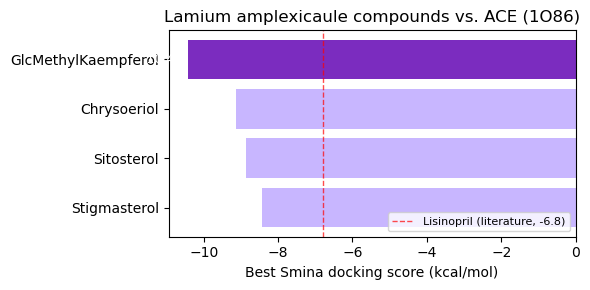

Saved figure: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/figures/lamium_amplexicaule_vs_ACE_scores.png


In [18]:
fig, ax = plt.subplots(figsize=(6, 3))
colors = ['#7b2cbf' if s == docking_df_amplexicaule_ACE['Best_Smina_Score_kcal_mol'].min() else '#c8b6ff'
          for s in docking_df_amplexicaule_ACE['Best_Smina_Score_kcal_mol']]
ax.barh(docking_df_amplexicaule_ACE['Compound'], docking_df_amplexicaule_ACE['Best_Smina_Score_kcal_mol'], color=colors)
ax.set_xlabel('Best Smina docking score (kcal/mol)')
ax.set_title('Lamium amplexicaule compounds vs. ACE (1O86)')
ax.invert_yaxis()
for i, v in enumerate(docking_df_amplexicaule_ACE['Best_Smina_Score_kcal_mol']):
    ax.text(v - 0.15, i, f"{v:.2f}", va='center', ha='right', fontsize=9, color='white')

# Reference line: lisinopril's published ACE docking score (-6.8 kcal/mol)
ax.axvline(-6.8, color='red', linestyle='--', linewidth=1, alpha=0.7, label='Lisinopril (literature, -6.8)')
ax.legend(loc='lower right', fontsize=8)

plt.tight_layout()

fig_path_amplexicaule_ACE = os.path.join(FIGURES_DIR, 'lamium_amplexicaule_vs_ACE_scores.png')
plt.savefig(fig_path_amplexicaule_ACE, dpi=300, bbox_inches='tight')
plt.show()
print("Saved figure:", fig_path_amplexicaule_ACE)


### 7.6. ProLif interaction fingerprints -- Lamium_amplexicaule vs ACE (each compound, own cell)

`n_jobs=1` avoids a multiprocessing/pickling crash in this environment;
`to_dataframe()` takes no arguments in ProLif 2.2.1.

In [19]:
prot_fp = mda.Universe("1O86_clean_H_fix.pdb")  # fix_protein() output
prot_fp = plf.Molecule.from_mda(prot_fp)


In [20]:
# ---- ProLif: Chrysoeriol ----
lig_suppl_Chrysoeriol = list(plf.sdf_supplier(smina_out_sdf_Chrysoeriol))
fp_Chrysoeriol = plf.Fingerprint()
fp_Chrysoeriol.run_from_iterable(lig_suppl_Chrysoeriol, prot_fp, n_jobs=1)
results_df_Chrysoeriol = fp_Chrysoeriol.to_dataframe()

print("=== Chrysoeriol ===")
display(results_df_Chrysoeriol)

net_Chrysoeriol = fp_Chrysoeriol.plot_lignetwork(lig_suppl_Chrysoeriol[0], kind="frame", frame=0, rotation=270)
net_png_Chrysoeriol = os.path.join(FIGURES_DIR, "Chrysoeriol_1O86_2Dnetwork.png")
net_Chrysoeriol.save_png(net_png_Chrysoeriol)
print("Saved network figure:", net_png_Chrysoeriol)


  0%|          | 0/10 [00:00<?, ?it/s]

=== Chrysoeriol ===


ligand            UNL1                                                       \
protein        ASN70.A   GLU162.A   HIS353.A   SER355.A   VAL380.A HIS383.A   
interaction VdWContact VdWContact VdWContact VdWContact VdWContact  HBDonor   
Frame                                                                         
0                 True      False      False       True      False    False   
1                 True      False      False       True      False     True   
2                False      False      False      False      False    False   
3                False       True       True      False       True    False   
4                False       True      False      False       True    False   
5                 True      False      False      False      False    False   
6                False      False      False      False       True    False   
7                 True      False      False      False      False    False   
8                False      False      False      False      False    False   
9                False      False       True      False       True    False   

ligand                                                 ...             \
protein                  GLU384.A GLU411.A             ...   ASP415.A   
interaction VdWContact VdWContact  HBDonor VdWContact  ... VdWContact   
Frame                                                  ...              
0                False      False    False       True  ...      False   
1                 True       True    False       True  ...      False   
2                False      False    False      False  ...       True   
3                False      False    False      False  ...      False   
4                False      False    False      False  ...       True   
5                False      False     True       True  ...      False   
6                False      False    False      False  ...       True   
7                False      False    False      False  ...      False   
8                False      False    False      False  ...       True   
9                False      False    False      False  ...      False   

ligand                                                                       \
protein     ASP453.A              PHE457.A   PHE512.A   HIS513.A   VAL518.A   
interaction  HBDonor VdWContact VdWContact VdWContact VdWContact VdWContact   
Frame                                                                         
0              False      False      False       True      False       True   
1              False      False      False       True      False       True   
2              False      False       True      False      False      False   
3              False       True      False      False      False      False   
4              False      False      False      False      False      False   
5              False      False      False       True      False       True   
6               True       True      False      False      False      False   
7              False      False      False       True      False       True   
8              False       True      False      False      False      False   
9              False      False      False      False       True       True   

ligand                                        
protein       TYR520.A   TYR523.A   PHE527.A  
interaction VdWContact VdWContact VdWContact  
Frame                                         
0                False       True      False  
1                False       True      False  
2                 True      False      False  
3                False      False       True  
4                False      False      False  
5                False       True      False  
6                False      False       True  
7                False       True      False  
8                False      False       True  
9                False      False      False  

[10 rows x 21 columns]

TypeError: LigNetwork.save_png() takes 1 positional argument but 2 were given

In [ ]:
# ---- ProLif: Stigmasterol ----
lig_suppl_Stigmasterol = list(plf.sdf_supplier(smina_out_sdf_Stigmasterol))
fp_Stigmasterol = plf.Fingerprint()
fp_Stigmasterol.run_from_iterable(lig_suppl_Stigmasterol, prot_fp, n_jobs=1)
results_df_Stigmasterol = fp_Stigmasterol.to_dataframe()

print("=== Stigmasterol ===")
display(results_df_Stigmasterol)

net_Stigmasterol = fp_Stigmasterol.plot_lignetwork(lig_suppl_Stigmasterol[0], kind="frame", frame=0, rotation=270)
net_png_Stigmasterol = os.path.join(FIGURES_DIR, "Stigmasterol_1O86_2Dnetwork.png")
net_Stigmasterol.save_png(net_png_Stigmasterol)
print("Saved network figure:", net_png_Stigmasterol)


In [ ]:
# ---- ProLif: GlcMethylKaempferol ----
lig_suppl_GlcMethylKaempferol = list(plf.sdf_supplier(smina_out_sdf_GlcMethylKaempferol))
fp_GlcMethylKaempferol = plf.Fingerprint()
fp_GlcMethylKaempferol.run_from_iterable(lig_suppl_GlcMethylKaempferol, prot_fp, n_jobs=1)
results_df_GlcMethylKaempferol = fp_GlcMethylKaempferol.to_dataframe()

print("=== GlcMethylKaempferol ===")
display(results_df_GlcMethylKaempferol)

net_GlcMethylKaempferol = fp_GlcMethylKaempferol.plot_lignetwork(lig_suppl_GlcMethylKaempferol[0], kind="frame", frame=0, rotation=270)
net_png_GlcMethylKaempferol = os.path.join(FIGURES_DIR, "GlcMethylKaempferol_1O86_2Dnetwork.png")
net_GlcMethylKaempferol.save_png(net_png_GlcMethylKaempferol)
print("Saved network figure:", net_png_GlcMethylKaempferol)


In [ ]:
# ---- ProLif: Sitosterol ----
lig_suppl_Sitosterol = list(plf.sdf_supplier(smina_out_sdf_Sitosterol))
fp_Sitosterol = plf.Fingerprint()
fp_Sitosterol.run_from_iterable(lig_suppl_Sitosterol, prot_fp, n_jobs=1)
results_df_Sitosterol = fp_Sitosterol.to_dataframe()

print("=== Sitosterol ===")
display(results_df_Sitosterol)

net_Sitosterol = fp_Sitosterol.plot_lignetwork(lig_suppl_Sitosterol[0], kind="frame", frame=0, rotation=270)
net_png_Sitosterol = os.path.join(FIGURES_DIR, "Sitosterol_1O86_2Dnetwork.png")
net_Sitosterol.save_png(net_png_Sitosterol)
print("Saved network figure:", net_png_Sitosterol)


### 7.7. Figure -- best-scoring compound vs. the real native ligand (lisinopril)

In [ ]:
best_row_amplexicaule_ACE = docking_df_amplexicaule_ACE.iloc[0]
best_compound_amplexicaule_ACE = best_row_amplexicaule_ACE['Compound']
print("Best-scoring compound:", best_compound_amplexicaule_ACE, "|", best_row_amplexicaule_ACE['Best_Smina_Score_kcal_mol'], "kcal/mol")

best_sdf_amplexicaule_ACE = {
    "Chrysoeriol": smina_out_sdf_Chrysoeriol,
    "Stigmasterol": smina_out_sdf_Stigmasterol,
    "GlcMethylKaempferol": smina_out_sdf_GlcMethylKaempferol,
    "Sitosterol": smina_out_sdf_Sitosterol,
}[best_compound_amplexicaule_ACE]

view = py3Dmol.view()
view.removeAllModels()
view.setViewStyle({'style':'outline','color':'black','width':0.1})

view.addModel(open(RECEPTOR_PDB,'r').read(), format='pdb')
Prot = view.getModel()
Prot.setStyle({'cartoon':{'arrows':True, 'tubes':True, 'style':'oval', 'color':'white'}})
view.addSurface(py3Dmol.VDW, {'opacity':0.6,'color':'white'})

view.addModel(open(NATIVE_LIG,'r').read(), format='mol2')
ref_m = view.getModel()
ref_m.setStyle({}, {'stick':{'colorscheme':'magentaCarbon','radius':0.2}})

results_amp_ACE = Chem.SDMolSupplier(best_sdf_amplexicaule_ACE)
p_amp_ACE = Chem.MolToMolBlock(results_amp_ACE[0], False)
print('Reference (lisinopril): Magenta | Best compound pose: Cyan')
print('Pose: {} | Score: {}'.format(results_amp_ACE[0].GetProp('Pose'), results_amp_ACE[0].GetProp('Score')))

view.addModel(p_amp_ACE, 'mol')
x = view.getModel()
x.setStyle({}, {'stick':{'colorscheme':'cyanCarbon','radius':0.2}})

view.zoomTo()
view.show()
